# 43 · Value iteration and policy iteration on FrozenLake

In [1]:
import numpy as np, gymnasium as gym, matplotlib.pyplot as plt

ARROWS = {0: "←", 1: "↓", 2: "→", 3: "↑"}

def transitions(env):
    P = env.unwrapped.P
    nS, nA = env.observation_space.n, env.action_space.n
    return P, nS, nA

def q_from_v(P, V, s, nA, gamma):
    return np.array([sum(p * (r + gamma * V[s2] * (not done)) for p, s2, r, done in P[s][a]) for a in range(nA)])

def value_iteration(env, gamma=0.99, tol=1e-8):
    P, nS, nA = transitions(env)
    V, sweeps, deltas = np.zeros(nS), 0, []
    while True:
        V_new = np.array([q_from_v(P, V, s, nA, gamma).max() for s in range(nS)])
        deltas.append(np.abs(V_new - V).max()); V = V_new; sweeps += 1
        if deltas[-1] < tol:
            break
    pi = np.array([q_from_v(P, V, s, nA, gamma).argmax() for s in range(nS)])
    return V, pi, deltas

def policy_evaluation(P, pi, nS, gamma, tol=1e-10):
    V = np.zeros(nS)
    while True:
        V_new = np.array([sum(p * (r + gamma * V[s2] * (not d)) for p, s2, r, d in P[s][pi[s]]) for s in range(nS)])
        if np.abs(V_new - V).max() < tol:
            return V_new
        V = V_new

def policy_iteration(env, gamma=0.99):
    P, nS, nA = transitions(env)
    pi, iters = np.zeros(nS, int), 0
    while True:
        V = policy_evaluation(P, pi, nS, gamma)
        new_pi = np.array([q_from_v(P, V, s, nA, gamma).argmax() for s in range(nS)])
        iters += 1
        if np.array_equal(new_pi, pi):
            return V, pi, iters
        pi = new_pi

def show(env, V, pi, title, ax):
    desc = env.unwrapped.desc.astype(str); n = desc.shape[0]
    ax.imshow(V.reshape(n, n), cmap="viridis")
    for s in range(n * n):
        r, c = divmod(s, n)
        txt = desc[r, c] if desc[r, c] in "HG" else ARROWS[pi[s]]
        ax.text(c, r, f"{txt}\n{V[s]:.2f}", ha="center", va="center", color="w", fontsize=9)
    ax.set_title(title); ax.axis("off")

def evaluate(env, pi, n=1000, seed=0):
    wins = 0
    for i in range(n):
        s, _ = env.reset(seed=seed + i)
        done = False
        while not done:
            s, r, te, tr, _ = env.step(int(pi[s])); done = te or tr
        wins += r
    return wins / n

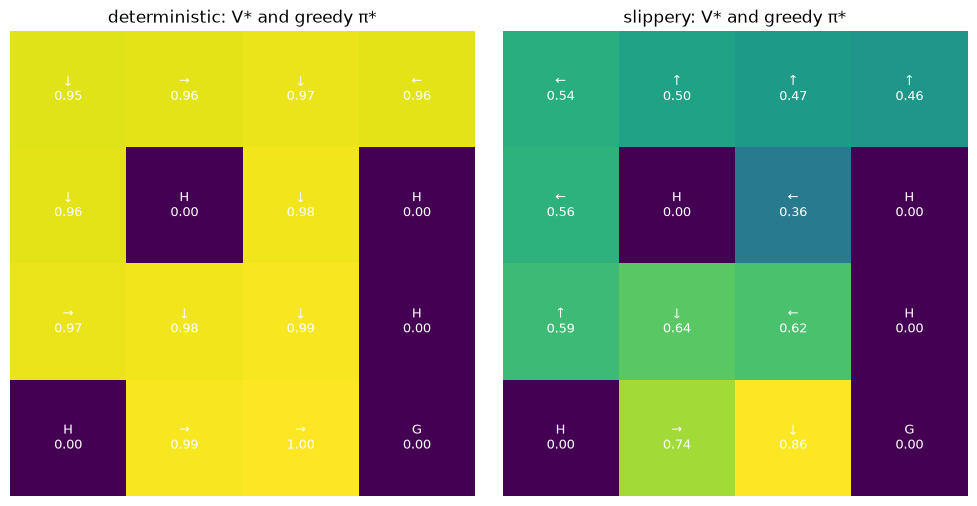

deterministic value iteration: 7 sweeps, success rate of π* = 1.000


slippery      value iteration: 438 sweeps, success rate of π* = 0.755


In [2]:
det = gym.make("FrozenLake-v1", is_slippery=False)
slip = gym.make("FrozenLake-v1", is_slippery=True)
fig, axes = plt.subplots(1, 2, figsize=(10, 5))
results = {}
for ax, (name, env) in zip(axes, [("deterministic", det), ("slippery", slip)]):
    V, pi, deltas = value_iteration(env)
    results[name] = (V, pi, deltas)
    show(env, V, pi, f"{name}: V* and greedy π*", ax)
plt.tight_layout(); plt.show()
for name, env in [("deterministic", det), ("slippery", slip)]:
    print(f"{name:13s} value iteration: {len(results[name][2])} sweeps, success rate of π* = {evaluate(env, results[name][1]):.3f}")

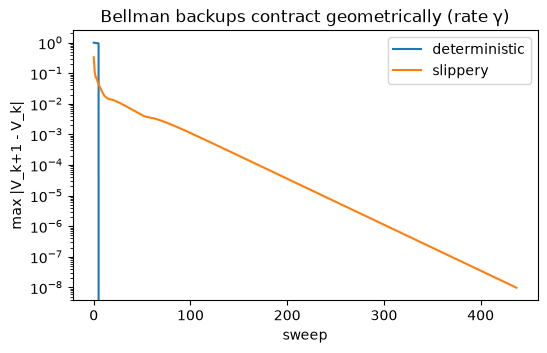

In [3]:
plt.figure(figsize=(6, 3.5))
for name in results:
    plt.semilogy(results[name][2], label=name)
plt.xlabel("sweep"); plt.ylabel("max |V_k+1 - V_k|"); plt.title("Bellman backups contract geometrically (rate γ)"); plt.legend(); plt.show()

In [4]:
for name, env in [("deterministic", det), ("slippery", slip)]:
    Vp, pip, iters = policy_iteration(env)
    print(f"{name:13s} policy iteration: {iters} improvement steps | same V as value iteration: {np.allclose(Vp, results[name][0], atol=1e-6)}")

deterministic policy iteration: 7 improvement steps | same V as value iteration: True
slippery      policy iteration: 7 improvement steps | same V as value iteration: True


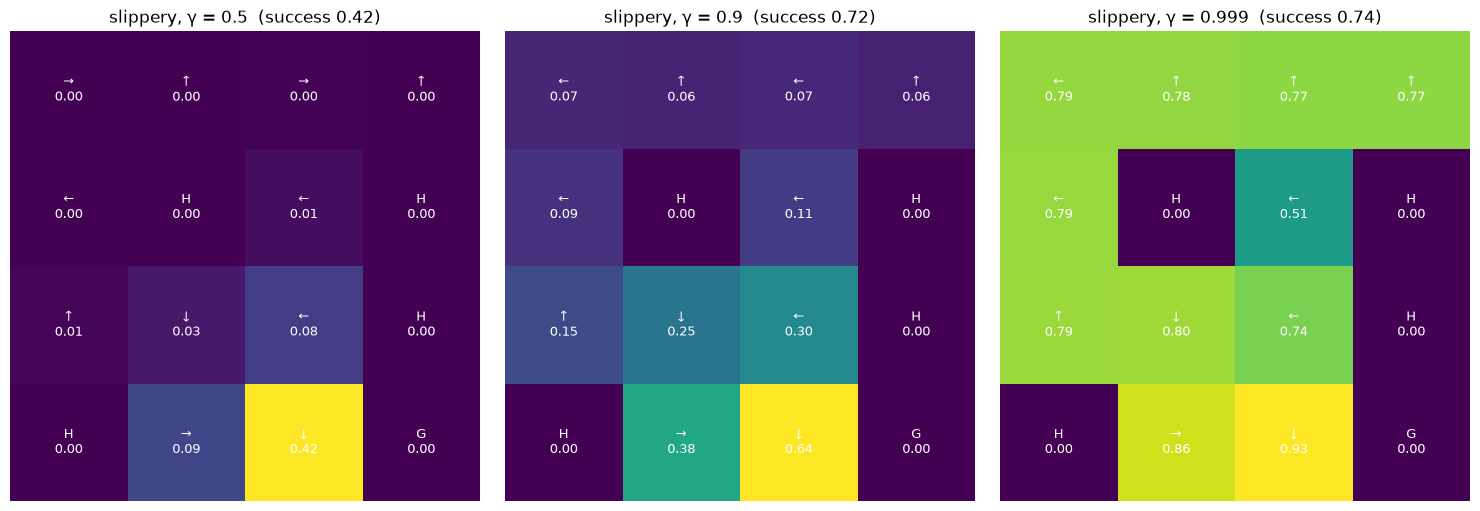

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(15, 5))
for ax, g in zip(axes, [0.5, 0.9, 0.999]):
    V, pi, _ = value_iteration(slip, gamma=g)
    show(slip, V, pi, f"slippery, γ = {g}  (success {evaluate(slip, pi, 500):.2f})", ax)
plt.tight_layout(); plt.show()